# 02: Reproducing the final report numbers before changing anything

*Phase 2.2 of the extension. The reasoning and the findings are explained in `docs/report.md`, section 2.2.*

Before the weather data, the physics or the economics are improved, the analysis has to be rebuilt exactly as the group submitted it. If the printed numbers cannot be recovered from the printed inputs, nothing built on them can be trusted, and any later improvement could not be separated from an arithmetic slip in the original.

Everything below comes from `configs/base.yaml` (inputs, each with the final report page it comes from) and the functions in `en630.dish`, `en630.load`, `en630.fuel` and `en630.economics`. `reproduce_final_report()` returns one row per printed figure. **No number is tuned to match**; where a figure does not follow from the report's own inputs it stays a documented gap.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from en630 import dish, economics
from en630.config import load_config
from en630.plotting import INK, SERIES, SURFACE, apply_theme, save
from en630.reproduce import reproduce_final_report

warnings.filterwarnings("ignore", category=FutureWarning)
apply_theme()
FIG = Path("../docs/figures")
FIG.mkdir(parents=True, exist_ok=True)

cfg = load_config()
table = reproduce_final_report(cfg)
n_match = int((table.verdict == "reproduces").sum())
n_gap = int((table.expect == "gap").sum())
print(f"{len(table)} printed figures rebuilt: {n_match} reproduce within the precision the report prints, {n_gap} do not.")

42 printed figures rebuilt: 35 reproduce within the precision the report prints, 7 do not.


## 1: The full comparison

*Tolerance* is half a unit in the last printed digit (or the stated rounding, noted in the table), not a free parameter.

In [2]:
show = table.assign(rel_diff_pct=(table.rel_diff * 100).round(4))[
    ["group", "quantity", "unit", "reported", "recomputed", "rel_diff_pct", "verdict"]
]
show.style.hide(axis="index").format({"reported": "{:,.6g}", "recomputed": "{:,.6g}"})

group,quantity,unit,reported,recomputed,rel_diff_pct,verdict
geometry,"declination, 17 May",deg,19.2636,19.2636,0.000000,reproduces
geometry,"hour angle, 12:30 IST",deg,-1.14457,-1.07227,6.316800,differs
geometry,"cos(theta), 17 May 12:30",-,0.943822,0.943822,0.000000,reproduces
optics,concentration ratio,-,90.3091,90.0309,0.308000,differs
optics,optical efficiency (reflectivity 0.92 as multiplied),-,0.607821,0.607822,0.000100,reproduces
optics,optical efficiency (reflectivity 0.9 as listed),-,0.607821,0.594608,2.173800,differs
receiver,sky temperature,K,298,298.785,0.263500,reproduces
receiver,receiver heat loss,W,618.29,618.175,0.018500,reproduces
receiver,energy absorbed by receiver,W,"4,708.9","4,708.95",0.001000,reproduces
receiver,receiver thermal efficiency,-,0.8687,0.868723,0.002700,reproduces


## 2: How close is each figure?

Each dot is one printed figure; the horizontal position is the relative difference between the report and the recomputation (symmetric log scale, so both tiny rounding differences and the large gaps are visible).

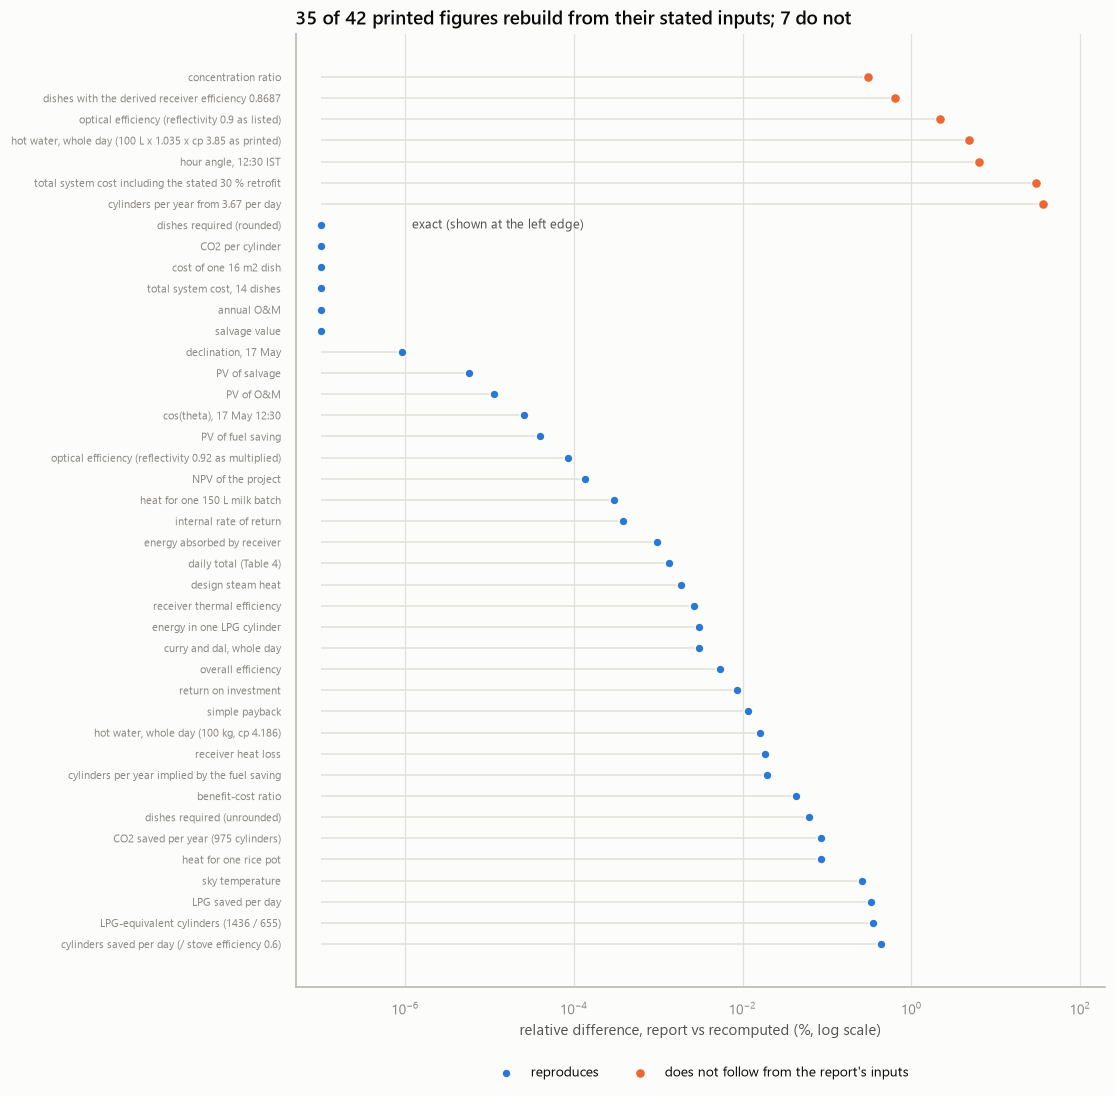

In [3]:
d = table.assign(pct=table.rel_diff * 100).sort_values(["expect", "pct"], ascending=[True, True]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9.5, 0.23 * len(d) + 1.6))
y = np.arange(len(d))[::-1]
is_gap = (d.expect == "gap").to_numpy()
ax.hlines(y, 1e-7, d.pct.clip(lower=1e-7), color="#e1e0d9", linewidth=1, zorder=1)
ax.scatter(d.pct.clip(lower=1e-7)[~is_gap], y[~is_gap], s=34, color=SERIES[0], edgecolor=SURFACE, linewidth=1, zorder=3, label="reproduces")
ax.scatter(d.pct.clip(lower=1e-7)[is_gap], y[is_gap], s=44, color=SERIES[1], edgecolor=SURFACE, linewidth=1, zorder=3, label="does not follow from the report's inputs")
ax.set_xscale("log")
ax.set_xlim(5e-8, 200)
ax.set_yticks(y, d.quantity, fontsize=7.5)
ax.set_xlabel("relative difference, report vs recomputed (%, log scale)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2)
ax.annotate("exact (shown at the left edge)", (1e-7, y[np.where((d.pct < 1e-7).to_numpy())[0][0]]), xytext=(1.2e-6, y[np.where((d.pct < 1e-7).to_numpy())[0][0]]), va="center", fontsize=8.5, color=INK["secondary"])
ax.set_title(f"{n_match} of {len(d)} printed figures rebuild from their stated inputs; {n_gap} do not")
save(fig, FIG / "final_report_reproduction_diff.png")
plt.show()

## 3: The gaps, one by one

In [4]:
gaps = table[table.expect == "gap"][["quantity", "reported", "recomputed", "note"]]
pd.set_option("display.max_colwidth", 200)
gaps.style.hide(axis="index").format({"reported": "{:,.6g}", "recomputed": "{:,.6g}"})

quantity,reported,recomputed,note
"hour angle, 12:30 IST",-1.14457,-1.07227,"Recomputed from the report's own equations; changes cos(theta) by less than 1e-5, so the optical efficiency is unaffected."
concentration ratio,90.3091,90.0309,11.65 / 0.1294 = 90.0309; the printed 90.3091 looks like two transposed digits.
optical efficiency (reflectivity 0.9 as listed),0.607821,0.594608,The text lists reflectivity 0.9 but the printed product uses 0.92.
"hot water, whole day (100 L x 1.035 x cp 3.85 as printed)",31.4,29.8856,"The inputs printed beside this result give 29.89 MJ, not 31.40 MJ."
dishes with the derived receiver efficiency 0.8687,14.02,13.9296,"The product uses 0.8626, not the derived 0.8687. With 0.8687 the unrounded count is 13.93, which still rounds to 14: the conclusion does not depend on the inconsistency."
cylinders per year from 3.67 per day,975,"1,333.69","3.67 cylinders a day for 365 days is about 1340 a year, not 975: the final report's CO2 and saving figures use a different, unexplained basis from its own daily figure."
total system cost including the stated 30 % retrofit,5.6e+06,7.28e+06,"The report lists a 120,000-per-dish retrofit just above the total but does not add it."


Four of the seven are typing or labelling slips with no effect on the result (hour angle, concentration ratio, the printed hot-water inputs, and the 0.00553 sky-temperature coefficient noted in the config). Three can move a conclusion and are tested next: the reflectivity actually used, the receiver efficiency used in sizing, and the retrofit allowance left out of the total cost.

## 4: Do the inconsistencies change the conclusions?

Three what-ifs, each changing one thing and leaving everything else as in the final report. These are **scenarios for sensitivity, not corrections**: which input the group really meant is for the authors to say.

In [5]:
op, sz, ec = cfg["optics"], cfg["sizing"], cfg["economics"]
dd = cfg["design_day"]
delta = dish.declination_deg(dd["day_of_year"])
cos_t = dish.cos_incidence(dd["tilt_deg"], dd["azimuth_deg"], delta, dd["hour_angle_reported_deg"], dd["latitude_used_deg"])
steam_j = table.set_index("quantity").recomputed["design steam heat"] * 1e6


def dishes(reflectivity, eta_rcv):
    eta_opt = dish.optical_efficiency(cos_t, reflectivity, op["receiver_absorptivity"])
    per_dish = dish.heat_per_dish_j(op["design_dni_w_m2"], op["reflector_area_m2"], sz["seconds_per_hour"],
                                    sz["design_hours_per_day"], eta_rcv, eta_opt)
    return steam_j / per_dish


def money(capital):
    om, salv = ec["om_fraction"] * capital, ec["salvage_fraction"] * capital
    parts = economics.npv_project(capital, ec["annual_fuel_saving_inr"], om, salv, ec["discount_rate"], ec["life_years"])
    return {
        "capital (lakh INR)": capital / 1e5,
        "simple payback (years)": economics.simple_payback_years(capital, ec["annual_fuel_saving_inr"]),
        "NPV (lakh INR)": parts["npv"] / 1e5,
        "benefit-cost ratio": economics.benefit_cost_ratio(parts, capital),
        "IRR (%)": 100 * economics.irr(capital, ec["annual_fuel_saving_inr"] - om, salv, ec["life_years"]),
    }


cap = ec["number_of_dishes"] * ec["dish_area_for_cost_m2"] * ec["cost_per_m2_inr"]
cap_retro = cap * (1 + ec["retrofit_fraction"])

sizing = pd.DataFrame({
    "unrounded dishes": [dishes(op["reflectivity_used"], sz["receiver_efficiency_used"]),
                         dishes(op["reflectivity_used"], 0.8687),
                         dishes(op["reflectivity_text"], sz["receiver_efficiency_used"])],
}, index=["as in the final report (reflectivity 0.92, receiver 0.8626)",
          "receiver efficiency as derived (0.8687)",
          "reflectivity as listed in the text (0.90)"])
sizing["rounded to nearest"] = sizing["unrounded dishes"].round()
sizing["rounded up"] = np.ceil(sizing["unrounded dishes"])
costs = pd.DataFrame({"as in the final report (retrofit not added)": money(cap),
                      "with the stated 30 % retrofit added": money(cap_retro)}).T
display(sizing.round(2))
display(costs.round(2))

,unrounded dishes,rounded to nearest,rounded up
"as in the final report (reflectivity 0.92, receiver 0.8626)",14.03,14.0,15.0
receiver efficiency as derived (0.8687),13.93,14.0,14.0
reflectivity as listed in the text (0.90),14.34,14.0,15.0


,capital (lakh INR),simple payback (years),NPV (lakh INR),benefit-cost ratio,IRR (%)
as in the final report (retrofit not added),56.0,4.27,35.92,1.56,20.12
with the stated 30 % retrofit added,72.8,5.55,16.76,1.20,13.82


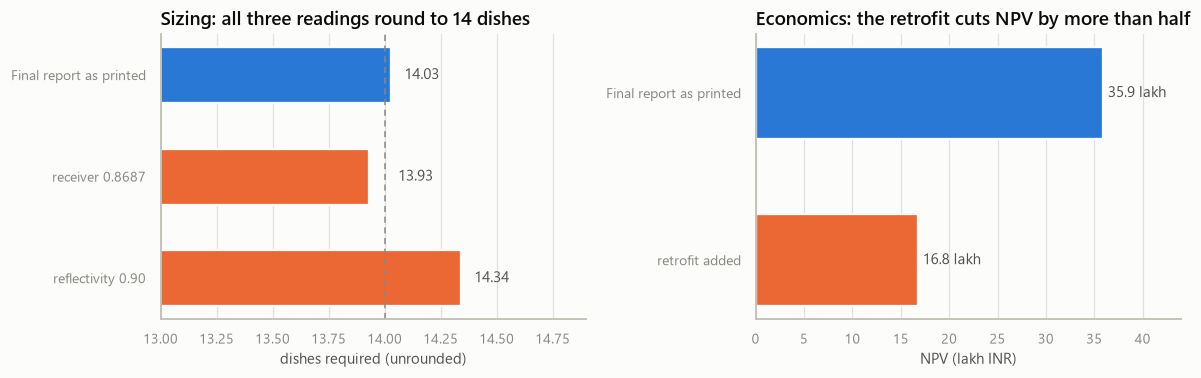

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
labels = ["Final report as printed", "receiver 0.8687", "reflectivity 0.90"]
vals = sizing["unrounded dishes"].to_numpy()
cols = [SERIES[0], SERIES[1], SERIES[1]]
ax = axes[0]
ax.barh(labels[::-1], vals[::-1], color=cols[::-1], height=0.55, edgecolor=SURFACE, linewidth=1.5)
for i, v in enumerate(vals[::-1]):
    ax.text(max(v, 14.0) + 0.06, i, f"{v:.2f}", va="center", fontsize=9.5, color=INK["secondary"])
ax.axvline(14, color=INK["muted"], linewidth=1, linestyle=(0, (4, 3)))
ax.set_xlim(13, 14.9)
ax.set_xlabel("dishes required (unrounded)")
ax.grid(axis="y", visible=False)
ax.set_title("Sizing: all three readings round to 14 dishes")

ax = axes[1]
names = ["Final report as printed", "retrofit added"]
npv = costs["NPV (lakh INR)"].to_numpy()
ax.barh(names[::-1], npv[::-1], color=[SERIES[1], SERIES[0]], height=0.55, edgecolor=SURFACE, linewidth=1.5)
for i, v in enumerate(npv[::-1]):
    ax.text(v + 0.5, i, f"{v:.1f} lakh", va="center", fontsize=9.5, color=INK["secondary"])
ax.set_xlim(0, 44)
ax.set_xlabel("NPV (lakh INR)")
ax.grid(axis="y", visible=False)
ax.set_title("Economics: the retrofit cuts NPV by more than half")
fig.tight_layout()
save(fig, FIG / "final_report_inconsistency_effects.png")
plt.show()

## What this notebook establishes, and what it does not

* **Established:** from the inputs the final report prints, 35 of its 42 recomputable figures come out within their printed precision, including the headline efficiencies (0.6078, 0.8687, 0.528), the 939.86 MJ daily load, 14 dishes, the 4.269-year payback, the NPV (INR 3,591,518, about INR 5 off because the report rounds one intermediate), the benefit-cost ratio and the IRR (20.116 %). The analysis as submitted is internally reproducible.
* **Established:** the seven gaps are catalogued, each with its cause. The sizing conclusion survives both inconsistencies: all three readings round to 14 dishes (14.03, 13.93 and 14.34 unrounded). Note that the final report rounds to the nearest dish, so its own 14.03 leaves the field 0.03 of a dish short; with the listed reflectivity of 0.90 the shortfall would be 0.34 of a dish, and rounding up instead would give 15 in both cases. The economics are sensitive to the omitted retrofit allowance: with it, NPV roughly halves and payback grows from 4.3 to 5.6 years, though the project still pays back within the dish life.
* **Not established:** which reading the authors intended; the 7-hour design day and the single design DNI of 665 W/m², which are inputs here and are revisited in the hourly simulation (notebook 04).
* **Next:** notebook 03 replaces the simplified optics with a corrected solar-geometry model and compares it with the original script.